In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np


In [5]:

from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve,auc,precision_recall_curve


In [ ]:
#import matplotlib.pyplot as plt
#import seaborn as sns
#import statsmodels.formula.api as smf

In [2]:
df = pd.read_csv("../injury_prediction_dataset.csv")
df.head(10)


,week_id,nr. sessions,total km,strength training,hours alternative,nr. sessions.1,total km.1,strength training.1,hours alternative.1,nr. sessions.2,...,hours alternative.4,nr. sessions.5,total km.5,strength training.5,hours alternative.5,nr. sessions.6,total km.6,strength training.6,hours alternative.6,injury
0,1,5,68.567523,3,3.906244,5,52.222091,3,0.465611,4,...,2.424763,3,31.676700,1,1.651326,6,26.699996,1,3.353339,0
1,2,6,63.735793,0,2.582410,4,22.896581,2,0.817822,5,...,0.465125,2,46.331224,2,1.180521,6,56.183691,2,0.451963,0
2,3,4,38.555768,2,3.738176,2,64.091307,0,0.337169,3,...,3.567458,3,49.611994,3,0.282279,4,90.266714,3,3.780326,0
3,4,6,51.272480,3,1.213542,4,76.694467,3,2.480126,3,...,0.188945,5,79.862625,0,1.650396,4,44.427168,0,3.771278,0
4,5,6,67.558107,3,3.127564,2,29.155053,0,0.589411,2,...,3.021249,6,89.303484,2,2.464694,4,40.667009,2,1.265419,0
5,6,3,59.741349,1,3.063435,3,44.434621,0,0.639852,2,...,1.494912,4,79.738810,3,0.713991,2,86.990773,2,2.476568,0
6,7,4,99.022842,2,2.766623,5,82.500556,3,0.056913,4,...,0.204662,5,71.718008,2,1.220107,6,44.479588,2,0.443017,0
7,8,4,30.915180,3,3.862556,3,49.273555,1,3.128360,5,...,3.371712,6,81.272006,0,2.556683,6,58.151358,3,0.336766,0
8,9,4,75.611564,2,1.574221,3,39.328197,3,3.249184,5,...,2.561841,5,79.079798,2,2.317299,3,22.499048,2,2.007178,0
9,10,6,52.345501,0,0.522869,2,73.776053,3,0.648090,6,...,0.035435,3,58.059975,0,3.475142,3,42.965740,1,0.198712,0


In [3]:

def get_simple_rule_baseline(df):
    prev_2w_avg = (df['total km.1'] + df['total km.2']) / 2.0

    score = df['total km'] / prev_2w_avg
    y_true = df["injury"]
    return {
        'y_true':y_true,
        'scores':score}

def get_noskill_baseline(df):

    CONSTANT_SCORE = 0.5
    y_true = df["injury"]

    no_skill_scores = np.ones(len(df)) * CONSTANT_SCORE

    return {
        'y_true':y_true,
        'scores':no_skill_scores
        }

In [12]:
import matplotlib.pyplot as plt

def plot_roc_pr_curves(y_true, y_scores,plot_label):
  """Trace les courbes ROC-AUC et PR-AUC côte à côte.

  Parameters:
  - y_true : Vraies étiquettes (0 ou 1)
  - y_scores : Probabilités prédites pour la classe positive (entre 0 et 1)
  """
  # 1. Calculs pour la courbe ROC
  fpr, tpr, _ = roc_curve(y_true, y_scores)
  roc_auc = auc(fpr, tpr)

  # 2. Calculs pour la courbe Precision-Recall
  precision, recall, _ = precision_recall_curve(y_true, y_scores)
  pr_auc = average_precision_score(y_true, y_scores)

  # Création de la figure avec deux sous-graphiques côte à côte
  fig, axes = plt.subplots(1, 2, figsize=(14, 6))

  # --- Graphique 1 : ROC-AUC ---
  axes[0].plot(
      fpr,
      tpr,
      color='darkorange',
      lw=2,
      label=f'Courbe ROC (AUC = {roc_auc:.3f})',
  )
  axes[0].plot(
      [0, 1],
      [0, 1],
      color='navy',
      lw=2,
      linestyle='--',
      label='Aléatoire (0.500)',
  )
  axes[0].set_xlim([0.0, 1.0])
  axes[0].set_ylim([0.0, 1.05])
  axes[0].set_xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
  axes[0].set_ylabel('Taux de Vrais Positifs (TPR / Rappel)', fontsize=12)
  axes[0].set_title('Courbe ROC model : '+ plot_label , fontsize=14, fontweight='bold')
  axes[0].legend(loc='lower right', fontsize=11)
  axes[0].grid(alpha=0.3)

  # --- Graphique 2 : PR-AUC ---
  axes[1].plot(
      recall,
      precision,
      color='blue',
      lw=2,
      label=f'Courbe PR (AP = {pr_auc:.3f})',
  )
  axes[1].set_xlim([0.0, 1.0])
  axes[1].set_ylim([0.0, 1.05])
  axes[1].set_xlabel('Rappel (Recall)', fontsize=12)
  axes[1].set_ylabel('Précision (Precision)', fontsize=12)
  axes[1].set_title('Courbe Précision-Rappel (PR) model : '+ plot_label , fontsize=14, fontweight='bold')
  axes[1].legend(loc='lower left', fontsize=11)
  axes[1].grid(alpha=0.3)

  plt.tight_layout()
  plt.show()


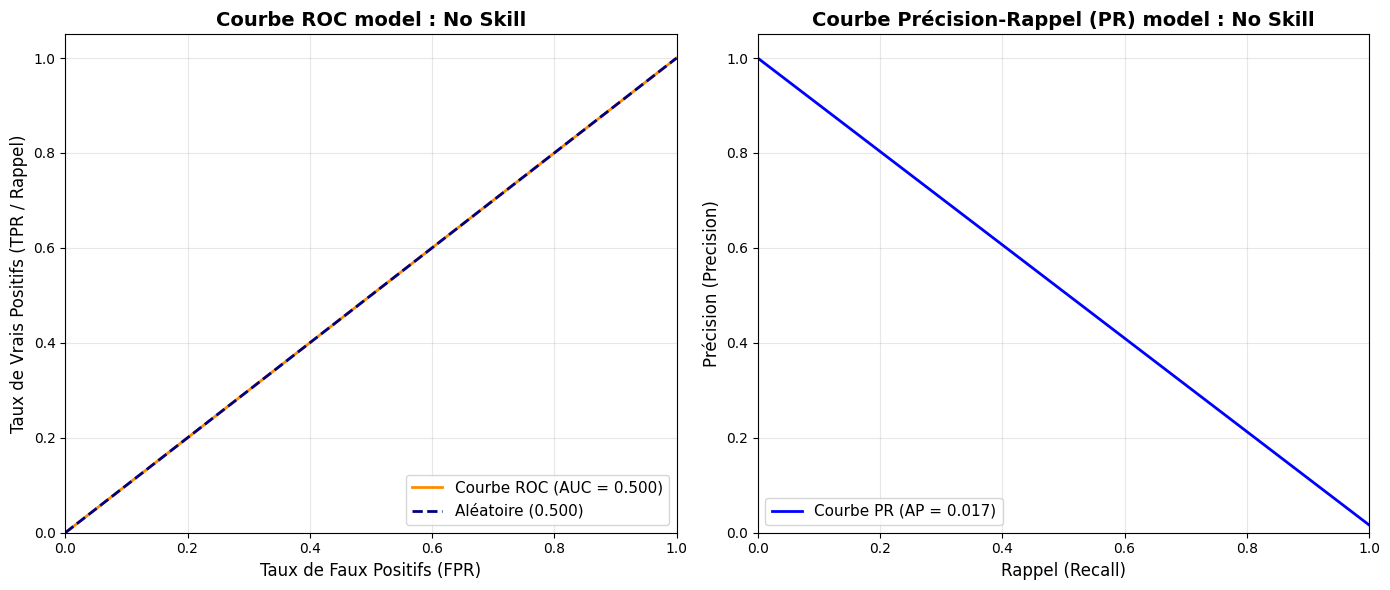

In [13]:
no_skill_scores = get_noskill_baseline(df)

plot_roc_pr_curves(no_skill_scores['y_true'], no_skill_scores['scores'], "No Skill")


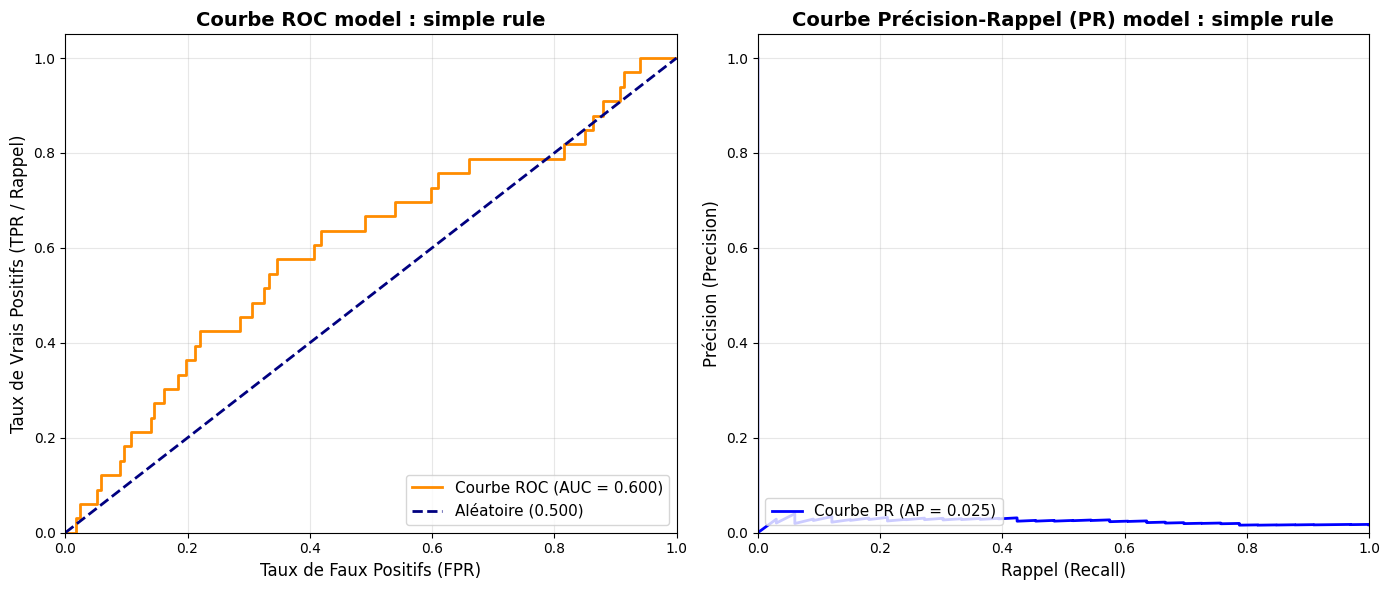

In [14]:
simple_rule_scores = get_simple_rule_baseline(df)
plot_roc_pr_curves(simple_rule_scores['y_true'], simple_rule_scores['scores'], "simple rule")
